# Дневник калорий: разведочный анализ данных

Чекпойнт 2, DL-трек.

Рассматриваем исходный датасет, проверяем качество фотографий и формируем
разметку отобранных фотографий. Разделение на выборки оставляем на следующий этап.
Все исходные фото сохраняем, причины исключений записываем в итоговый CSV.

Для проверки содержимого используем результаты полного
прохода Qwen3.5 4B и последующего ручного просмотра.

Ноутбук выполняется сверху вниз. Нужны папка `dataset/` с исходной разметкой
и фотографиями, а также каталог `review_results/` с файлами
`vlm_review.csv` и `human_review.csv` полного прохода.
Характеристики и хеши рассчитываются здесь, повторно запускать Ollama не нужно.
На выходе получаем `processed/metadata.csv`.


Структура входных файлов:

```text
EDA.ipynb
review_results/
    human_review.csv
    vlm_review.csv
dataset/
    metadata.csv
    папки_классов/
```

In [ ]:
# Подключаем библиотеки, задаём настройки и загружаем исходную разметку и результаты
# проверки.
import hashlib
import io
import warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as NotebookImage
from IPython.display import Markdown, display
from PIL import Image, ImageEnhance, ImageOps

In [2]:
current = Path.cwd().resolve()

ROOT = next(
    (
        p
        for p in [current, *current.parents]
        if (p / "dataset/metadata.csv").is_file()
        and (p / "review_results/vlm_review.csv").is_file()
        and (p / "review_results/human_review.csv").is_file()
    ),
    None,
)

assert ROOT is not None, "Откройте ноутбук из папки проекта"

DATA = ROOT / "dataset"
PROCESSED = ROOT / "processed"
PROCESSED.mkdir(exist_ok=True)

SEED = 109
MIN_IMAGES = 20
MIN_GROUPS = 5

plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "figure.dpi": 110,
        "pdf.fonttype": 42,
        "axes.grid": False,
    }
)

metadata = pd.read_csv(DATA / "metadata.csv")

REVIEW_RESULTS = ROOT / "review_results"
model = pd.read_csv(REVIEW_RESULTS / "vlm_review.csv").fillna("")
human = pd.read_csv(REVIEW_RESULTS / "human_review.csv").fillna("")

model_name = model["model"].iloc[0]

print("Корень проекта:", ROOT.name)
print("Исходных записей:", len(metadata), "| классов:", metadata["class"].nunique())
print("Модель:", model_name)

Корень проекта: repo_ready
Исходных записей: 50080 | классов: 156
Модель: qwen3.5:4b


In [3]:
def show_preview(fig):
    """Показать уменьшенное JPEG-превью графика в ноутбуке.

    Parameters
    ----------
    fig : matplotlib.figure.Figure
        Фигура, которую нужно вывести.

    Returns
    -------
    None
        Выводит изображение через display и закрывает исходную фигуру.

    Notes
    -----
    JPEG создаётся в памяти через BytesIO, файл на диске не появляется.
    """
    buffer = io.BytesIO()
    fig.savefig(buffer, format="jpeg", dpi=80, pil_kwargs={"quality": 80})
    display(NotebookImage(data=buffer.getvalue()))
    plt.close(fig)

## 1. Описание данных и задачи

Мы решаем задачу классификации: по фотографии нужно определить
один класс продукта. Несколько объектов одного класса допустимы, например
несколько яблок или кусков курицы. Разные продукты на одном фото могут сделать
единственную метку неоднозначной.

В Telegram-боте пользователь отправляет фото, подтверждает продукт и указывает
массу. Калорийность рассчитывается по справочнику и массе, а не определяется
классификатором по изображению. Детекция объектов и оценка порции по фото пока
не входят в задачу.

Исходная сборка получена из общей папки Google Drive в шести ZIP. В metadata.csv есть два столбца:
`path`, путь относительно dataset/, и `class`, метка продукта. Фотографии
разложены по папкам классов. Рамок, масок и массы продукта в разметке нет.

### Источники изображений

Мы собрали датасет из семи источников. Для нашей задачи используем единую метку продукта на фотографию, даже если исходный набор предназначался для детекции или оценки свежести.

| Источник | Что используем | Исходная разметка |
|---|---|---|
| [Chicken Meat](https://universe.roboflow.com/learndetect/chicken-meat/dataset/3) | Изображения куриного мяса | Детекция частей курицы; в сборке используется класс chicken |
| [Pork image](https://zenodo.org/records/21629593) | Изображения свинины | Исходная задача связана с оценкой цвета мяса; в сборке используется класс pork |
| [Meat Species and Hourly Freshness](https://data.mendeley.com/datasets/4tj9t3n6vj/1) | Говядина и баранина | Вид мяса и свежесть; в сборке используются beef и mutton |
| [Egg Variety Recognition, Freshness Assessment, and Nutritional Estimation](https://data.mendeley.com/datasets/49msr3ksxj/2) | Изображения яиц | Разновидность и свежесть яиц; в сборке используется chicken_egg |
| [Bakery](https://universe.roboflow.com/fpt-ycwb3/bakery-3yhtj) | Изображения выпечки | Детекция: тип продукта и его расположение на фото |
| [ImageNet-21k (gmongaras/Imagenet21K)](https://huggingface.co/datasets/gmongaras/Imagenet21K) | Часть изображений продуктов | Классификация изображений |
| [Google Open Images V7](https://storage.googleapis.com/openimages/web/index.html) | Изображения, отобранные по меткам нужных классов | Для сборки использованы метки классов изображений |

В наборе говядины и баранины авторы увеличили 4500 исходных изображений до 18000 с помощью аугментаций. Для итогового классификационного набора яиц авторы указывают, что аугментации не применялись. Эти сведения относятся к первоисточникам: число оригиналов и аугментаций именно в нашей сборке по текущей разметке не разделяем.


После анализа сравним исходный объём с результатом проверки содержимого
и версией, которую берём в обучение.

In [4]:
# Смотрим первые строки исходной разметки.
display(metadata.head())

,path,class
0,almond/dry_fruit_0076865a8b448cdbb5c5.jpg,almond
1,almond/dry_fruit_00f05a0a6e825da62c7a.jpg,almond
2,almond/dry_fruit_012641614be4ef3b64b2.jpg,almond
3,almond/dry_fruit_0238f63a0a7d43d72413.jpg,almond
4,almond/dry_fruit_0284ef420cd85020ff5e.jpg,almond


In [5]:
# Получаем общие статистики исходной разметки.
display(metadata.describe(include="all"))

,path,class
count,50080,50080
unique,50080,156
top,zucchini/d9aaaa061a6f7dc5.jpg,mutton
freq,1,7907


In [6]:
# Выводим список классов.
class_list = pd.DataFrame({"class": sorted(metadata["class"].dropna().unique())})
display(class_list)

,class
0,almond
1,apple
2,apricot
3,artichoke
4,arugula
...,...
151,walnut
152,watercress
153,watermelon
154,winter_melon


## 2. Объём и баланс исходного датасета

Подсчитываем фотографии по классам через `value_counts()`. Классов много,
поэтому разбиваем диаграмму на несколько частей с общей шкалой высоты.

In [7]:
# Считаем количество фотографий и долю каждого класса.
raw_counts = metadata["class"].value_counts()

raw_balance = raw_counts.rename_axis("class").reset_index(name="images")

raw_balance["share_percent"] = (raw_balance["images"] / len(metadata) * 100).round(2)
display(raw_balance.head(15))

,class,images,share_percent
0,mutton,7907,15.79
1,beef,7571,15.12
2,chicken,3218,6.43
3,mushroom,1896,3.79
4,pork,1707,3.41
5,chicken_egg,1215,2.43
6,tomato,1197,2.39
7,strawberry,1089,2.17
8,donut,949,1.89
9,apple,773,1.54


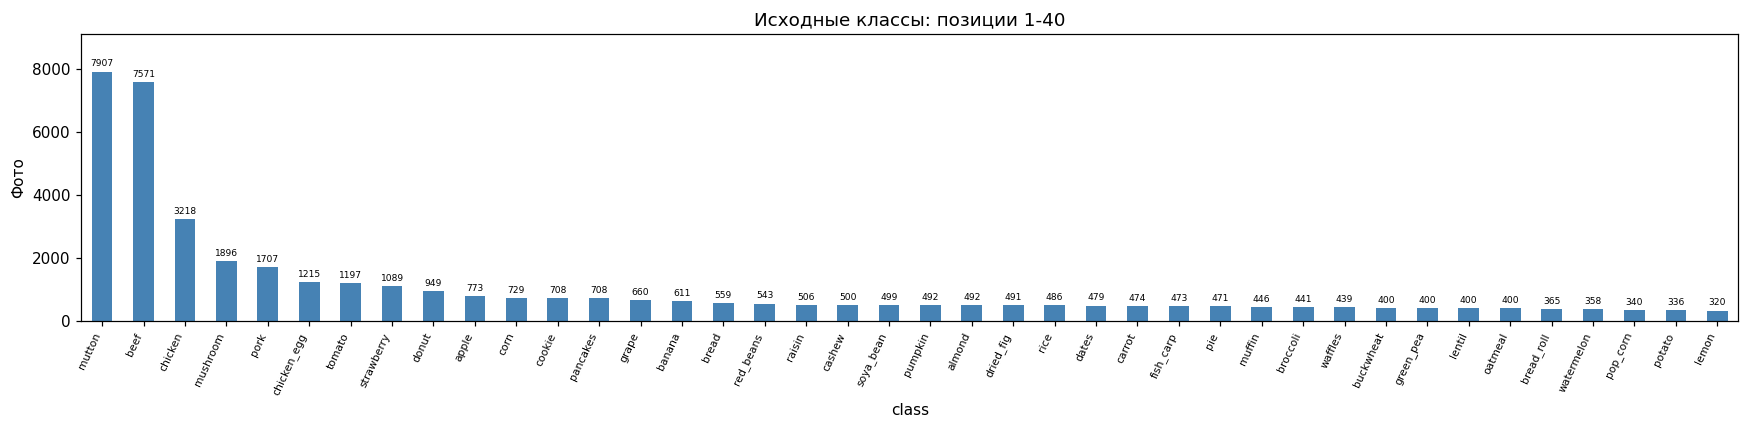

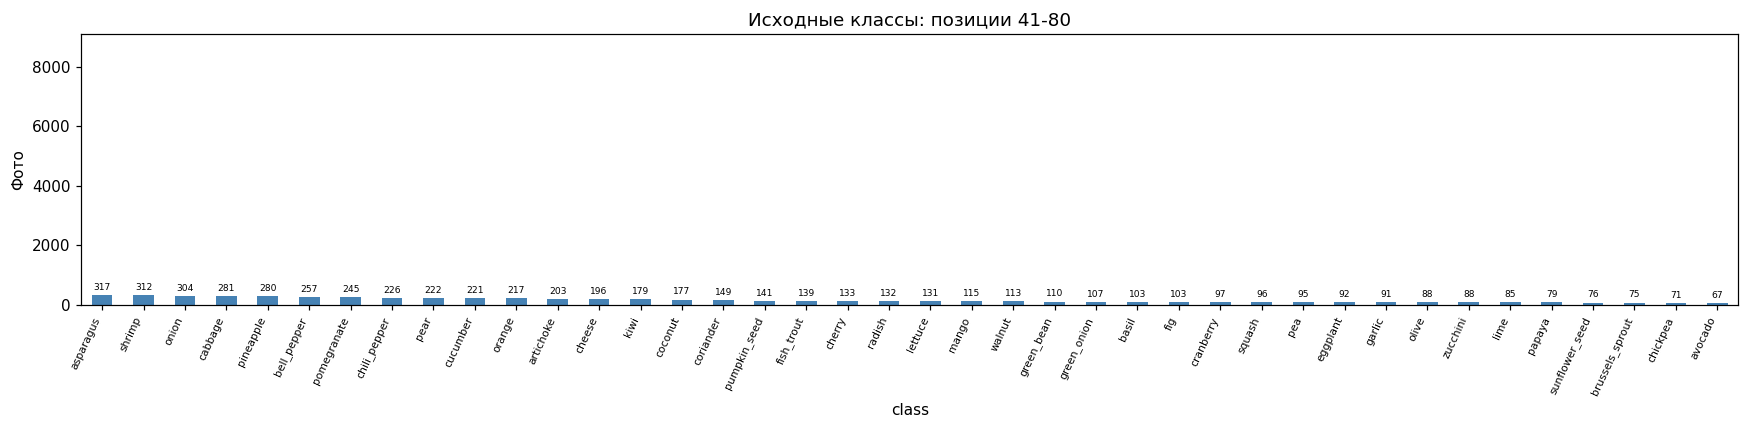

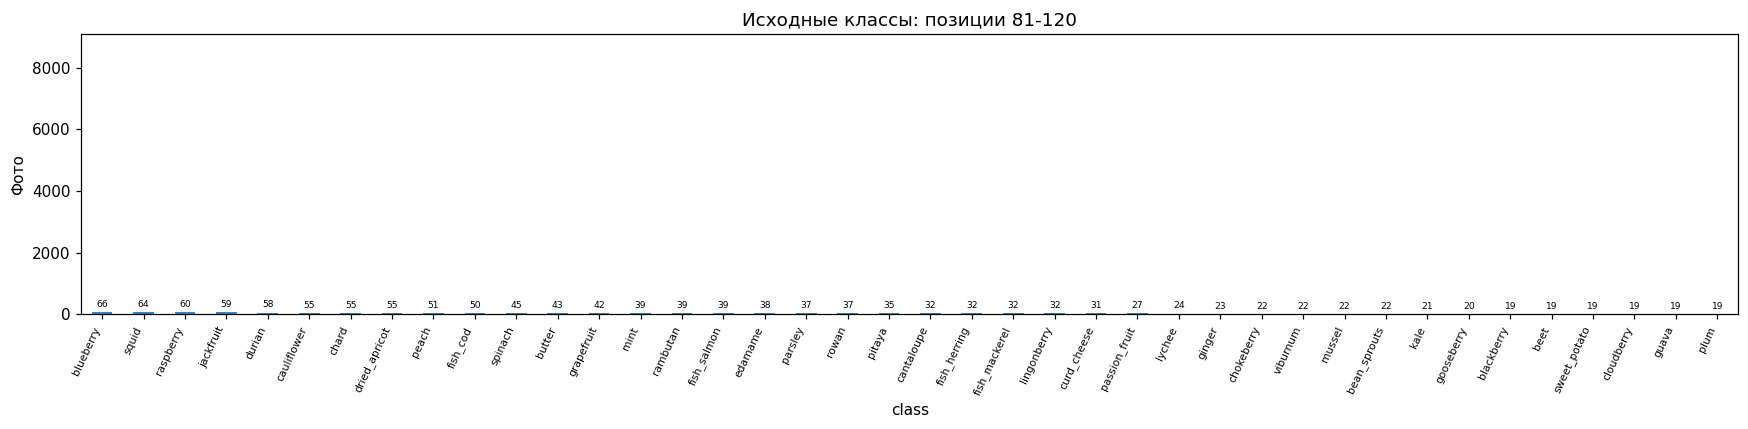

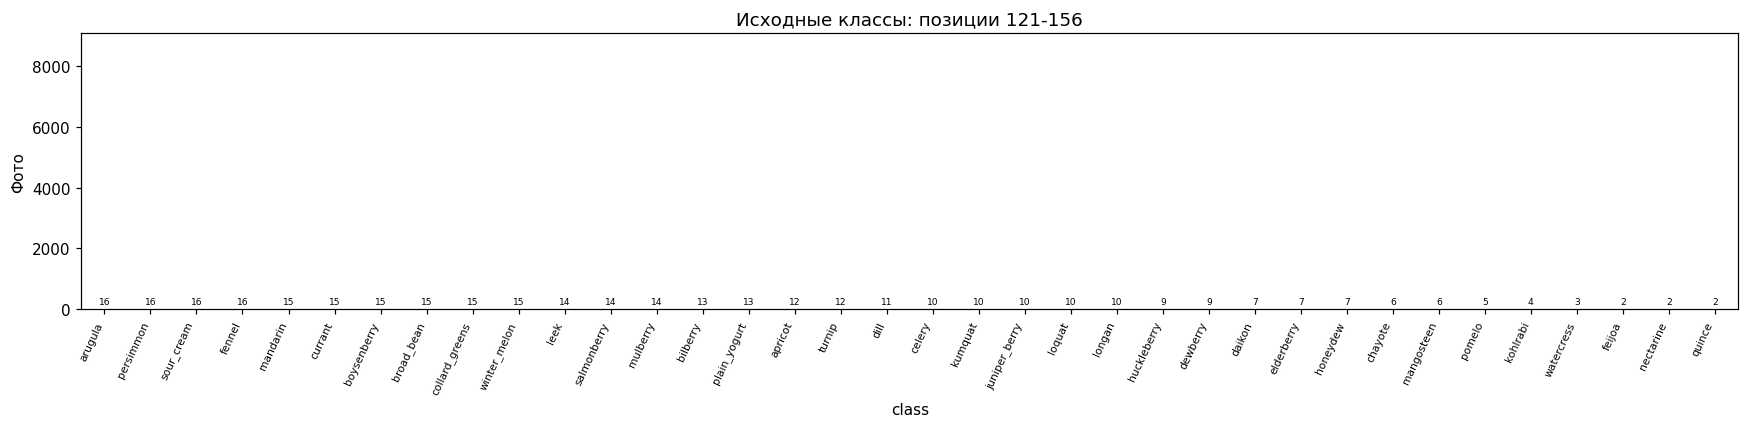

In [8]:
# Строим распределение фотографий по классам.
for start in range(0, len(raw_counts), 40):
    part = raw_counts.iloc[start : start + 40]
    ax = part.plot.bar(figsize=(16, 4), color="steelblue")
    ax.bar_label(ax.containers[0], fontsize=6, padding=2)

    ax.set_ylim(0, raw_counts.max() * 1.15)
    ax.set_title(f"Исходные классы: позиции {start + 1}-{start + len(part)}")
    ax.set_ylabel("Фото")

    plt.xticks(rotation=65, ha="right", fontsize=7)
    plt.tight_layout()
    plt.show()
    plt.close()

In [9]:
display(
    Markdown(f"""В исходной сборке {len(metadata):,} фото и {len(raw_counts)} классов.
Самый большой класс: {raw_counts.index[0]} ({raw_counts.iloc[0]} фото).
Минимальное число фото в классе: {raw_counts.min()}.
Классов с менее чем 20 фото: {int((raw_counts < 20).sum())}.
Такой дисбаланс делает общую accuracy недостаточной для оценки модели.
В дальнейшем нужны macro-F1, recall по классам и матрица ошибок.""")
)

В исходной сборке 50,080 фото и 156 классов.
Самый большой класс: mutton (7907 фото).
Минимальное число фото в классе: 2.
Классов с менее чем 20 фото: 42.
Такой дисбаланс делает общую accuracy недостаточной для оценки модели.
В дальнейшем нужны macro-F1, recall по классам и матрица ошибок.

## 3. Характеристики изображений

За один проход читаем исходные фотографии через Pillow и рассчитываем размеры,
яркость, резкость и хеши. Готовые отчёты не нужны. На 50 тысячах фото этот шаг
занимает время; прогресс показываем каждые 5000 файлов.

Размеры считаем после EXIF-поворота, формат и цветовой режим до преобразований.
Среднюю яркость считаем по всему изображению в режиме L без уменьшения. Фон тоже влияет на это значение.

Для ускорения читаем четыре файла параллельно. Результаты остаются в памяти,
при повторном выполнении этой ячейки измерения считаются заново.

In [10]:
# Определяем функцию измерения характеристик фотографии.
def measure_image(row):
    """Прочитать фотографию и рассчитать её технические признаки.

    Parameters
    ----------
    row : tuple[str, str]
        Пара (путь относительно DATA, класс продукта).

    Returns
    -------
    dict
        Одна строка будущих метаданных: ключи path и class, состояние файла,
        размеры, яркость, резкость, формат, режим, хеши, error и warnings.
        Если измерение недоступно, остаётся NaN или пустая строка.

    Notes
    -----
    Использует глобальный путь DATA, исходное фото не изменяет.
    Ошибки чтения перехватывает и записывает в поле error.
    """

    relative, class_name = row
    path = (DATA / str(relative)).resolve()

    safe = path.is_relative_to(DATA.resolve())
    exists = safe and path.is_file()

    result = dict(
        path=relative,
        **{"class": class_name},
        safe_path=safe,
        exists=exists,
        file_bytes=np.nan,
        mtime_ns=np.nan,
        width=np.nan,
        height=np.nan,
        aspect_ratio=np.nan,
        resolution_mp=np.nan,
        file_size_kb=np.nan,
        brightness=np.nan,
        sharpness=np.nan,
        format="",
        color_mode="",
        file_sha256="",
        pixel_sha256="",
        dhash="",
        error="",
        warnings="",
    )
    try:
        if not exists:
            raise FileNotFoundError("Файл отсутствует или путь вне dataset/")

        info = path.stat()
        result.update(
            file_bytes=info.st_size,
            mtime_ns=info.st_mtime_ns,
            file_size_kb=info.st_size / 1024,
        )
        content = path.read_bytes()

        result["file_sha256"] = hashlib.sha256(content).hexdigest()

        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")

            with Image.open(io.BytesIO(content)) as original:
                result.update(format=original.format, color_mode=original.mode)

                image = ImageOps.exif_transpose(original).convert("RGB")
                width, height = image.size
                result.update(
                    width=width,
                    height=height,
                    aspect_ratio=width / height,
                    resolution_mp=width * height / 1_000_000,
                )

                result["pixel_sha256"] = hashlib.sha256(
                    str(image.size).encode() + image.tobytes()
                ).hexdigest()

                gray = image.convert("L")
                result["brightness"] = float(np.asarray(gray).mean())

                small = np.asarray(gray.resize((9, 8), Image.Resampling.LANCZOS))
                bits = small[:, 1:] > small[:, :-1]

                result["dhash"] = np.packbits(bits).tobytes().hex()

                gray.thumbnail((256, 256))
                values = np.asarray(gray, dtype=np.float32)

                laplacian = (
                    values[:-2, 1:-1]
                    + values[2:, 1:-1]
                    + values[1:-1, :-2]
                    + values[1:-1, 2:]
                    - 4 * values[1:-1, 1:-1]
                )
                result["sharpness"] = float(laplacian.var()) if laplacian.size else 0.0
            result["warnings"] = "; ".join(str(w.message) for w in caught)

    except Exception as error:
        result["error"] = f"{type(error).__name__}: {error}"
    return result

In [11]:
# Измеряем фотографии и проверяем соответствие результатов исходной разметке.
assert not metadata["path"].duplicated().any(), "В разметке повторяются пути"

started = perf_counter()
measurements = []

with ThreadPoolExecutor(max_workers=4) as pool:
    rows = metadata[["path", "class"]].itertuples(index=False, name=None)

    for count, result in enumerate(pool.map(measure_image, rows), start=1):
        measurements.append(result)
        if count % 5000 == 0 or count == len(metadata):
            print(
                f"{count}/{len(metadata)} фото, {(perf_counter() - started) / 60:.1f} мин"
            )

characteristics = pd.DataFrame(measurements)

quality = characteristics[
    ["path", "class", "file_sha256", "pixel_sha256", "dhash", "sharpness", "error"]
].copy()

file_state = characteristics[["path", "safe_path", "exists"]].copy()

characteristics = characteristics.drop(
    columns=["safe_path", "exists", "file_sha256", "pixel_sha256", "dhash", "sharpness"]
)

for name, table in [("Модель", model), ("Ручная проверка", human)]:
    assert not table["path"].duplicated().any(), f"{name}: повторные пути"
    assert set(table["path"]) == set(metadata["path"]), f"{name}: другой состав данных"
    expected = metadata.set_index("path")["class"]
    assert table["class"].eq(table["path"].map(expected)).all(), (
        f"{name}: изменились классы"
    )

5000/50080 фото, 0.2 мин


10000/50080 фото, 0.3 мин


15000/50080 фото, 0.5 мин


20000/50080 фото, 0.7 мин


25000/50080 фото, 0.8 мин


30000/50080 фото, 1.1 мин


35000/50080 фото, 1.2 мин


40000/50080 фото, 1.4 мин


45000/50080 фото, 3.2 мин


50000/50080 фото, 3.4 мин


50080/50080 фото, 3.4 мин


In [12]:
# Смотрим статистики размеров, яркости, форматов и цветовых режимов.
image_stats = characteristics.loc[characteristics["error"].fillna("").eq("")].copy()

numeric_columns = [
    "width",
    "height",
    "aspect_ratio",
    "resolution_mp",
    "file_size_kb",
    "brightness",
]
display(
    image_stats[numeric_columns + ["format", "color_mode", "class"]]
    .describe(include="all")
    .round(3)
)

,width,height,aspect_ratio,resolution_mp,file_size_kb,brightness,format,color_mode,class
count,50080.000,50080.000,50080.000,50080.000,50080.000,50080.000,50080,50080,50080
unique,NaN,NaN,NaN,NaN,NaN,NaN,3,3,156
top,NaN,NaN,NaN,NaN,NaN,NaN,JPEG,RGB,mutton
freq,NaN,NaN,NaN,NaN,NaN,NaN,50068,50043,7907
mean,754.070,702.988,1.107,0.874,212.800,102.311,NaN,NaN,NaN
std,615.158,643.351,0.272,2.378,448.932,45.658,NaN,NaN,NaN
min,79.000,34.000,0.221,0.004,2.194,1.904,NaN,NaN,NaN
25%,512.000,512.000,1.000,0.262,43.751,64.876,NaN,NaN,NaN
50%,512.000,512.000,1.000,0.262,70.873,101.242,NaN,NaN,NaN
75%,1024.000,768.000,1.333,0.700,180.218,132.199,NaN,NaN,NaN


In [13]:
display(image_stats["format"].value_counts().to_frame("Фото"))

,Фото
format,
JPEG,50068
MPO,11
WEBP,1


In [14]:
display(image_stats["color_mode"].value_counts().to_frame("Фото"))

,Фото
color_mode,
RGB,50043
L,33
CMYK,4


In [15]:
display(
    image_stats.groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
    .head(10)
    .to_frame("Фото")
)

Фото
width height       
512   512     19900
1024  768      4780
      683      2088
      1024     1499
384   384      1307
2976  4464     1004
768   1024      992
4464  2976      703
640   640       532
576   768       440

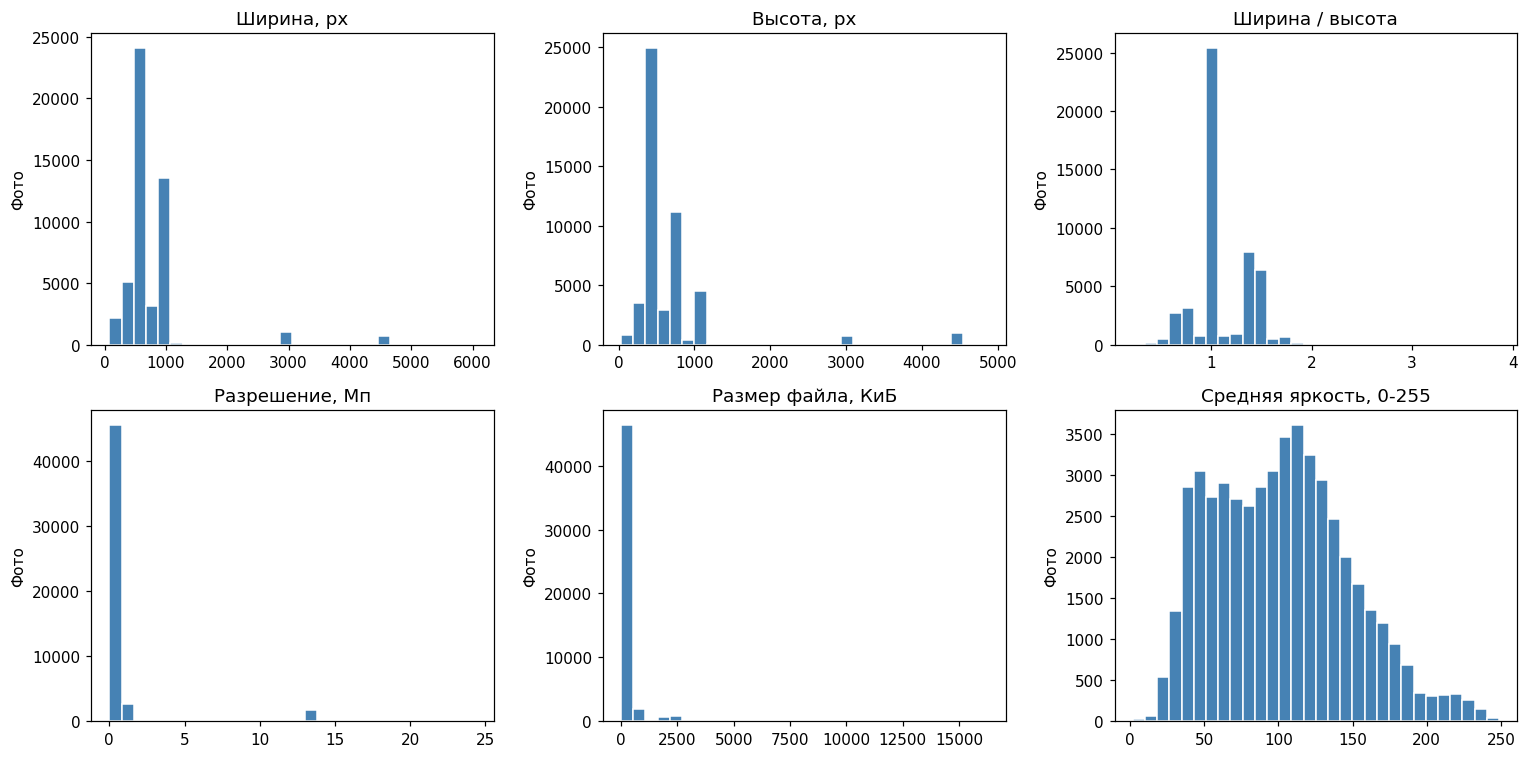

In [16]:
# Строим распределения характеристик и матрицу корреляций.
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
titles = [
    "Ширина, px",
    "Высота, px",
    "Ширина / высота",
    "Разрешение, Мп",
    "Размер файла, КиБ",
    "Средняя яркость, 0-255",
]

for ax, column, title in zip(axes.flat, numeric_columns, titles):
    ax.hist(image_stats[column].dropna(), bins=30, color="steelblue", edgecolor="white")
    ax.set_title(title)
    ax.set_ylabel("Фото")
plt.tight_layout()
plt.show()
plt.close()

In [17]:
# Сравниваем характеристики изображений наиболее многочисленных классов.
class_properties = image_stats.groupby("class")[numeric_columns].median()
display(class_properties.loc[raw_counts.head(10).index].round(2))

,width,height,aspect_ratio,resolution_mp,file_size_kb,brightness
class,,,,,,
mutton,512.0,512.0,1.00,0.26,52.34,62.14
beef,512.0,512.0,1.00,0.26,58.05,50.94
chicken,397.0,392.0,1.00,0.15,46.58,150.04
mushroom,1024.0,768.0,1.33,0.79,269.79,96.09
pork,2976.0,4464.0,0.67,13.28,2229.63,82.08
chicken_egg,512.0,512.0,1.00,0.26,32.31,29.36
tomato,1024.0,768.0,1.33,0.79,226.72,113.40
strawberry,1024.0,768.0,1.33,0.79,242.03,118.32
donut,384.0,384.0,1.00,0.20,38.46,119.23


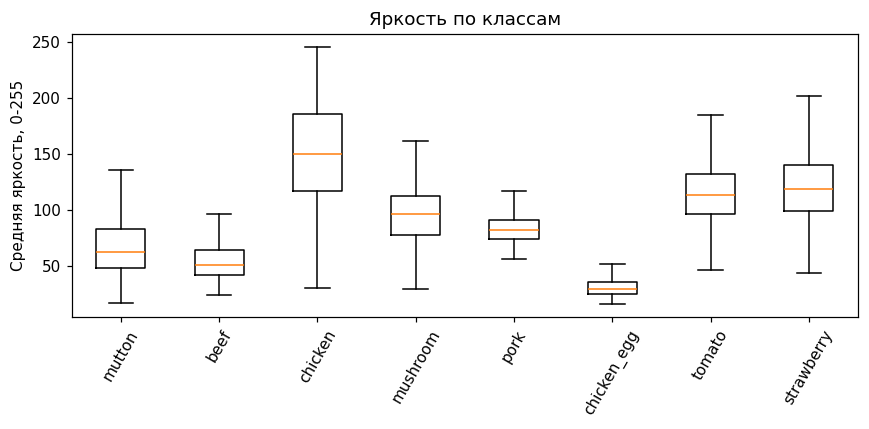

In [18]:
# Сравниваем яркость фотографий наиболее многочисленных классов.
top_classes = raw_counts.head(8).index
fig, ax = plt.subplots(figsize=(8, 4))
values = [
    image_stats.loc[image_stats["class"].eq(c), "brightness"].dropna()
    for c in top_classes
]
ax.boxplot(values, showfliers=False)
ax.set_xticks(range(1, len(top_classes) + 1))
ax.set_xticklabels(top_classes)
ax.tick_params(axis="x", rotation=60)
ax.set_title("Яркость по классам")
ax.set_ylabel("Средняя яркость, 0-255")
plt.tight_layout()
plt.show()
plt.close()

## 4. Качество данных

### 4.1. Пропуски, ошибки чтения и метки

Проверяем заполненность `path` и `class`, наличие файлов, чтение через Pillow
и совпадение класса с названием папки. Строки с такими ошибками исключаем
из версии для обучения и сохраняем в итоговой таблице с причиной.
Пустой комментарий человека допустим: решение хранится в отдельном столбце.

In [19]:
# Проверяем пропуски, файлы и метки, отмечаем кандидатов на выбросы.
missing_summary = pd.DataFrame(
    {"missing": metadata.isna().sum(), "percent": metadata.isna().mean() * 100}
)
display(missing_summary)

,missing,percent
path,0,0.0
class,0,0.0


In [20]:
print(
    "Доля пустых ячеек исходной разметки:", metadata.isna().sum().sum() / metadata.size
)

Доля пустых ячеек исходной разметки: 0.0


In [21]:
folder_class = (
    metadata["path"]
    .fillna("")
    .str.replace("\\", "/", regex=False)
    .str.split("/")
    .str[0]
)
empty_label = metadata[["path", "class"]].isna().any(axis=1) | metadata["class"].fillna(
    ""
).str.strip().eq("")
folder_mismatch = folder_class.ne(metadata["class"])

read_error_paths = set(quality.loc[quality["error"].fillna("").ne(""), "path"]) | set(
    characteristics.loc[characteristics["error"].fillna("").ne(""), "path"]
)
read_error = metadata["path"].isin(read_error_paths)

dimensions_bad = characteristics["width"].le(0) | characteristics["height"].le(0)
brightness_bad = ~characteristics["brightness"].between(0, 255)
image_extensions = {
    ".jpg",
    ".jpeg",
    ".png",
    ".webp",
    ".bmp",
    ".tif",
    ".tiff",
    ".gif",
    ".mpo",
}

actual_image_paths = {
    p.relative_to(DATA).as_posix()
    for p in DATA.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
}
unlabelled_files = pd.DataFrame(
    {"path": sorted(actual_image_paths - set(metadata["path"]))}
)
print("Фото без строки разметки:", len(unlabelled_files))

Фото без строки разметки: 0


In [22]:
checks = pd.DataFrame(
    {
        "Проверка": [
            "Пустая метка/путь",
            "Повторный путь",
            "Отсутствующий файл",
            "Небезопасный путь",
            "Метка отличается от папки",
            "Ошибка Pillow",
            "Неверные размеры",
            "Яркость вне 0-255",
        ],
        "Записей": [
            int(empty_label.sum()),
            int(metadata["path"].duplicated().sum()),
            int((~file_state["exists"]).sum()),
            int((~file_state["safe_path"]).sum()),
            int(folder_mismatch.sum()),
            int(read_error.sum()),
            int(dimensions_bad.sum()),
            int(brightness_bad.sum()),
        ],
    }
)
display(checks)

,Проверка,Записей
0,Пустая метка/путь,0
1,Повторный путь,0
2,Отсутствующий файл,0
3,Небезопасный путь,0
4,Метка отличается от папки,0
5,Ошибка Pillow,0
6,Неверные размеры,0
7,Яркость вне 0-255,0


In [23]:
outlier_flags = image_stats[["path", "class"]].copy()
outlier_flags["small_side"] = image_stats[["width", "height"]].min(axis=1).lt(128)
outlier_flags["extreme_ratio"] = ~image_stats["aspect_ratio"].between(1 / 3, 3)
outlier_flags["extreme_brightness"] = ~image_stats["brightness"].between(10, 245)
display(outlier_flags.iloc[:, 2:].sum().to_frame("Кандидатов"))

,Кандидатов
small_side,436
extreme_ratio,14
extreme_brightness,30


Фотографии с маленькой стороной, необычными пропорциями и крайней яркостью
отмечаем для просмотра. По этим порогам ничего автоматически не исключаем:
чёрный фон или светлая тарелка могут быть обычными условиями съёмки.

### 4.2. Дубли и похожие снимки

SHA-256 файла ищет побайтовые копии. Хеш RGB-пикселей с учётом размеров
находит одинаковое изображение после EXIF-поворота, даже если отличаются
метаданные файла. Для похожих снимков используем dHash. Совпадение dHash
считаем поводом держать фото в одной выборке, но не основанием удалять их.

In [24]:
# Ищем точные копии и совпадения хешей похожих фотографий.
duplicate_summary = []
duplicate_tables = {}
for key in ["file_sha256", "pixel_sha256", "dhash"]:
    valid_hashes = quality.loc[quality["error"].eq("") & quality[key].notna()]

    repeated = valid_hashes.loc[valid_hashes[key].duplicated(keep=False)].sort_values(
        key
    )

    groups = repeated.groupby(key).agg(
        images=("path", "size"), classes=("class", "nunique")
    )
    duplicate_tables[key] = repeated

    duplicate_summary.append(
        {
            "hash": key,
            "images_in_groups": len(repeated),
            "groups": len(groups),
            "extra_copies": int((groups["images"] - 1).sum()),
            "cross_class_groups": int(groups["classes"].gt(1).sum()),
        }
    )
display(pd.DataFrame(duplicate_summary))

,hash,images_in_groups,groups,extra_copies,cross_class_groups
0,file_sha256,0,0,0,0
1,pixel_sha256,4,2,2,0
2,dhash,3060,1452,1608,14


In [25]:
display(duplicate_tables["pixel_sha256"][["path", "class", "pixel_sha256"]])

,path,class,pixel_sha256
38485,pancakes/pancakes_104.jpg,pancakes,4e00efc106fd1fc00d5719fabadf941c75a1c1a045c8d0...
39184,pancakes/pancakes_97.jpg,pancakes,4e00efc106fd1fc00d5719fabadf941c75a1c1a045c8d0...
10915,bread/bread_404.jpg,bread,ef6d9188b02eff5c25b5e1a0c812043bed14b3ada8622a...
10916,bread/bread_405.jpg,bread,ef6d9188b02eff5c25b5e1a0c812043bed14b3ada8622a...


### 4.3. Проверка содержимого через Qwen3.5 4B и вручную

Используем завершённый полный проход. Модель получала фотографию и предполагаемый
класс, проверяла наличие другого продукта и соответствие метке. Все модельные
reject и unsure затем просмотрены вручную. Ручное решение имеет приоритет.

Люди, руки, посуда и упаковка сами по себе не повод отклонять фото.
Различимая другая еда или неверный класс могут быть поводом. Скрытые ингредиенты,
свежесть, массу и калорийность по фото не угадываем. Для составных классов,
например cookie, ингредиенты продукта не считаем отдельными объектами.

Модель могла ошибиться и среди keep. Отсутствие ручного решения для keep
не означает подтверждение человеком. Объяснение модели не равно достоверной
причине исключения, если она не записана отдельно при ручном просмотре.

In [26]:
# Объединяем решения модели и человека, применяем дополнительные ручные поправки.
assert model["decision"].isin(["keep", "reject", "unsure"]).all()
assert human["human_decision"].isin(["", "keep", "reject", "unsure"]).all()

review = model.merge(
    human[["path", "human_decision", "human_reason"]], on="path", validate="one_to_one"
)

extra_manual = pd.DataFrame(
    [
        {
            "path": "blackberry/da0fd6310080e889.jpg",
            "class": "blackberry",
            "decision": "reject",
            "reason": "Ежевика на блинах: видны разные продукты",
        },
        {
            "path": "blueberry/29c9e40a04e2ce96.jpg",
            "class": "blueberry",
            "decision": "reject",
            "reason": "Черника в выпечке: фото не одного вида продукта",
        },
    ]
)
assert not extra_manual["path"].duplicated().any()
assert extra_manual["decision"].isin(["keep", "reject"]).all()
assert set(extra_manual["path"]).issubset(set(metadata["path"]))
assert (
    extra_manual["class"]
    .eq(extra_manual["path"].map(metadata.set_index("path")["class"]))
    .all()
)

review["review_source"] = np.where(
    review["human_decision"].eq(""), "model_only", "human_full_pass"
)

for addition in extra_manual.to_dict("records"):
    mask = review["path"].eq(addition["path"])
    review.loc[mask, "human_decision"] = addition["decision"]
    review.loc[mask, "human_reason"] = addition["reason"]
    review.loc[mask, "review_source"] = "manual_eda"
display(extra_manual)

,path,class,decision,reason
0,blackberry/da0fd6310080e889.jpg,blackberry,reject,Ежевика на блинах: видны разные продукты
1,blueberry/29c9e40a04e2ce96.jpg,blueberry,reject,Черника в выпечке: фото не одного вида продукта


In [27]:
review["content_decision"] = "pending"
review.loc[
    review["decision"].eq("keep") & review["human_decision"].eq(""), "content_decision"
] = "keep"

manual_final = review["human_decision"].isin(["keep", "reject"])
review.loc[manual_final, "content_decision"] = review.loc[
    manual_final, "human_decision"
]

display(
    pd.crosstab(
        review["decision"], review["human_decision"].replace("", "Без ручной оценки")
    )
)

human_decision,keep,reject,Без ручной оценки
decision,,,
keep,0,2,40085
reject,243,5966,0
unsure,3143,641,0


In [28]:
display(review["content_decision"].value_counts().to_frame("Фото"))

,Фото
content_decision,
keep,43471
reject,6609


In [29]:
print(
    "Модельный keep без ручной оценки:",
    int((review["decision"].eq("keep") & review["human_decision"].eq("")).sum()),
)

Модельный keep без ручной оценки: 40085


In [30]:
print("Ручных причин заполнено:", int(human["human_reason"].str.strip().ne("").sum()))

Ручных причин заполнено: 0


In [31]:
assert not review["content_decision"].eq("pending").any(), (
    "Сначала разберите оставшиеся ручные решения"
)

display(pd.crosstab(review["image_type"], review["content_decision"]))

content_decision,keep,reject
image_type,,
collage,5,132
drawing,20,123
packaging_only,29,2
photo,43417,6352


In [32]:
display(pd.crosstab(review["other_food"], review["content_decision"]))

content_decision,keep,reject
other_food,,
no,43182,306
yes,289,6303


## 5. Визуальный анализ

Выбираем по одному случайному фото каждого класса с SEED.
На сетках сравниваем фон, ракурс и вид продукта. Ниже отдельно смотрим
кандидатов с низкой резкостью и примеры отклонённых фотографий.

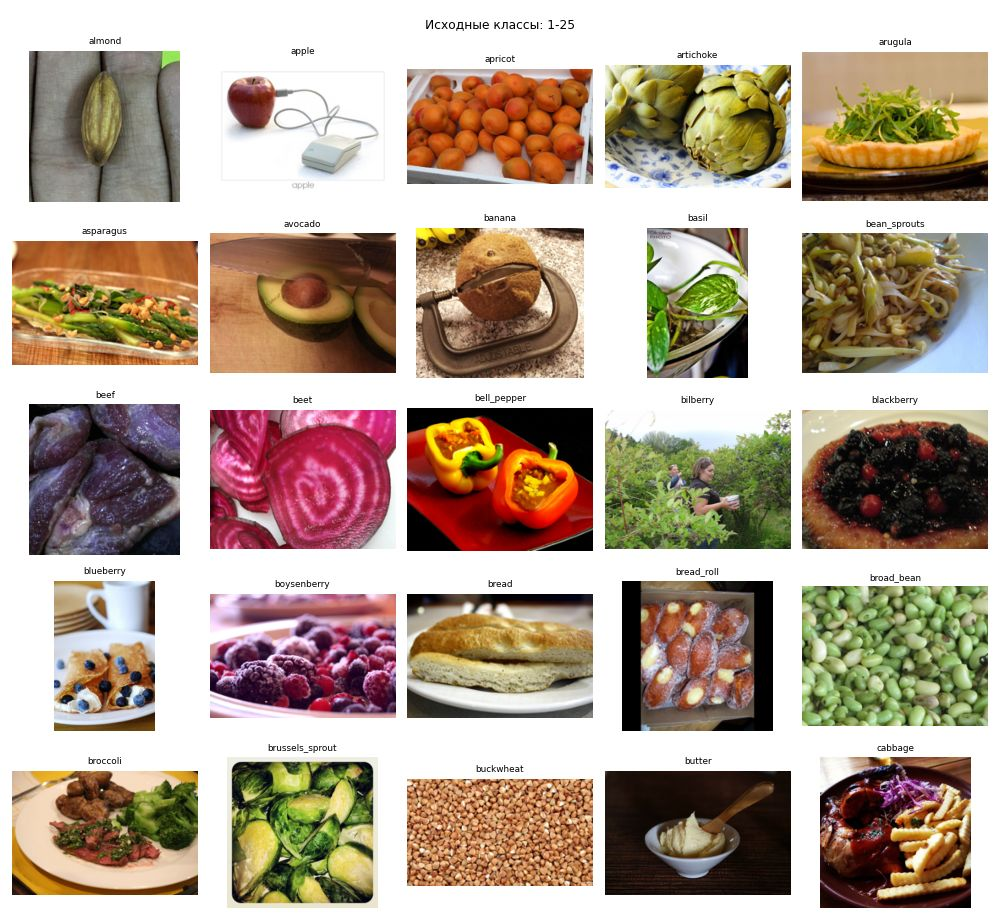

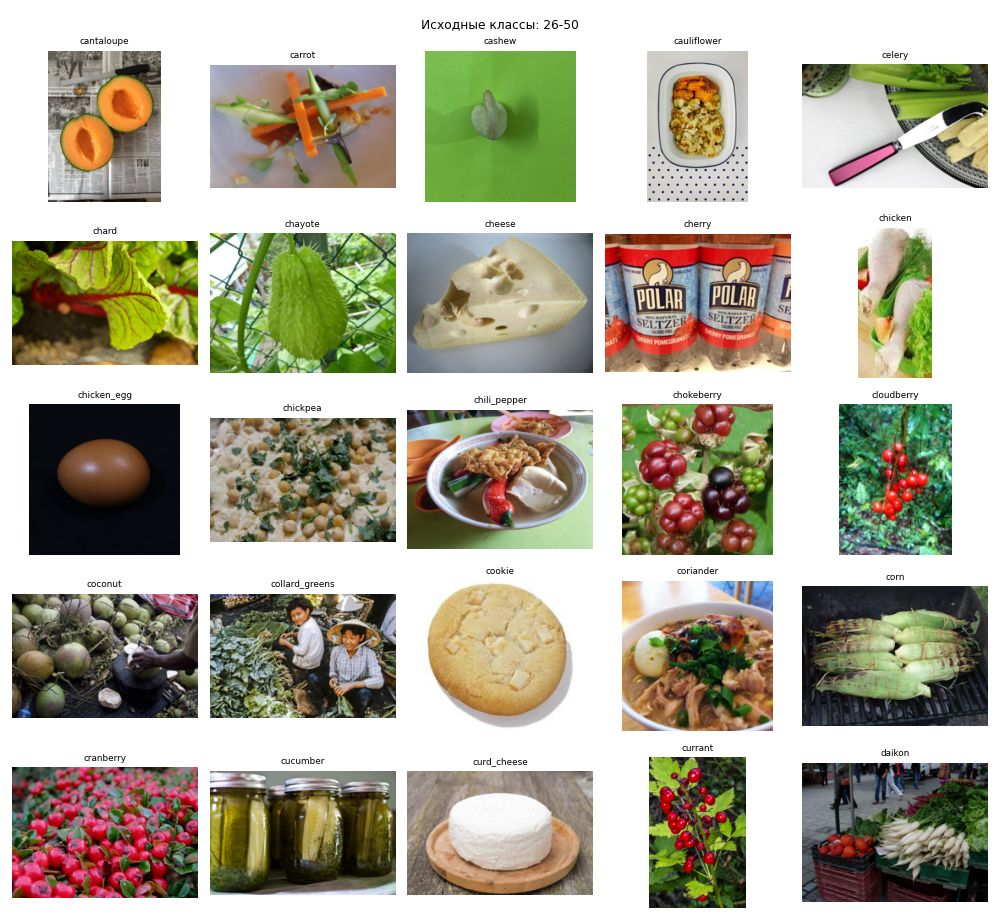

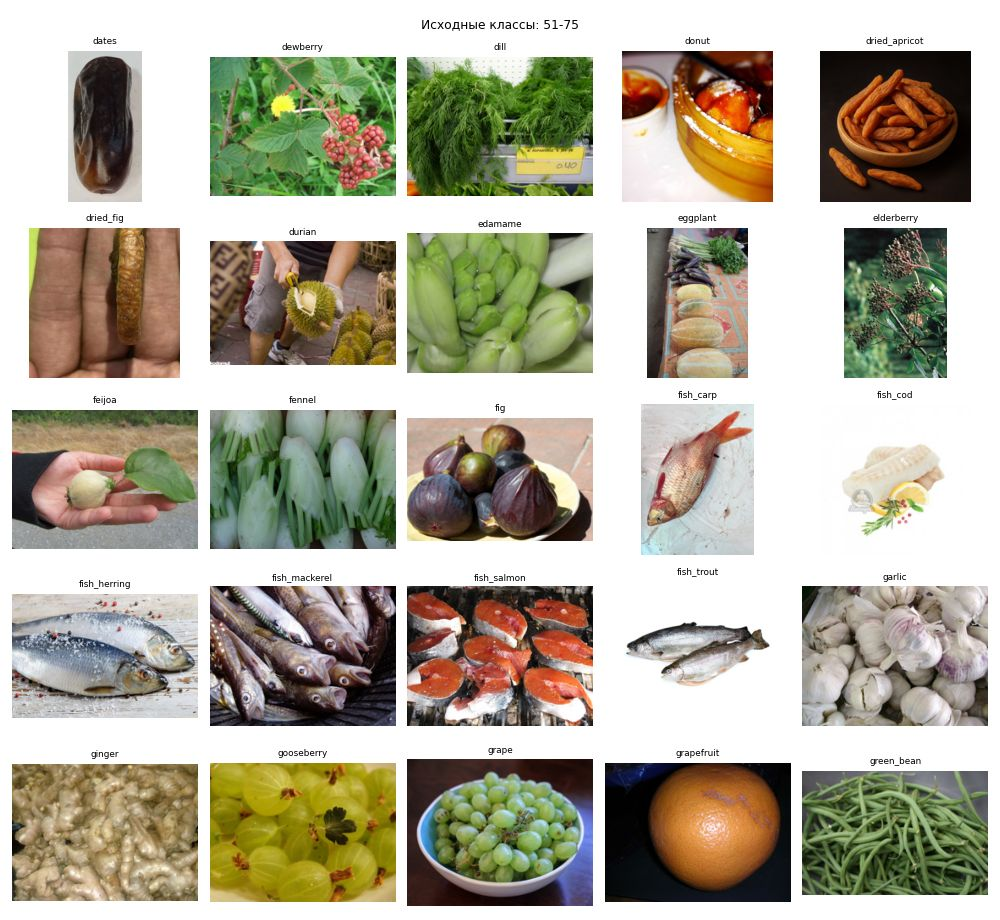

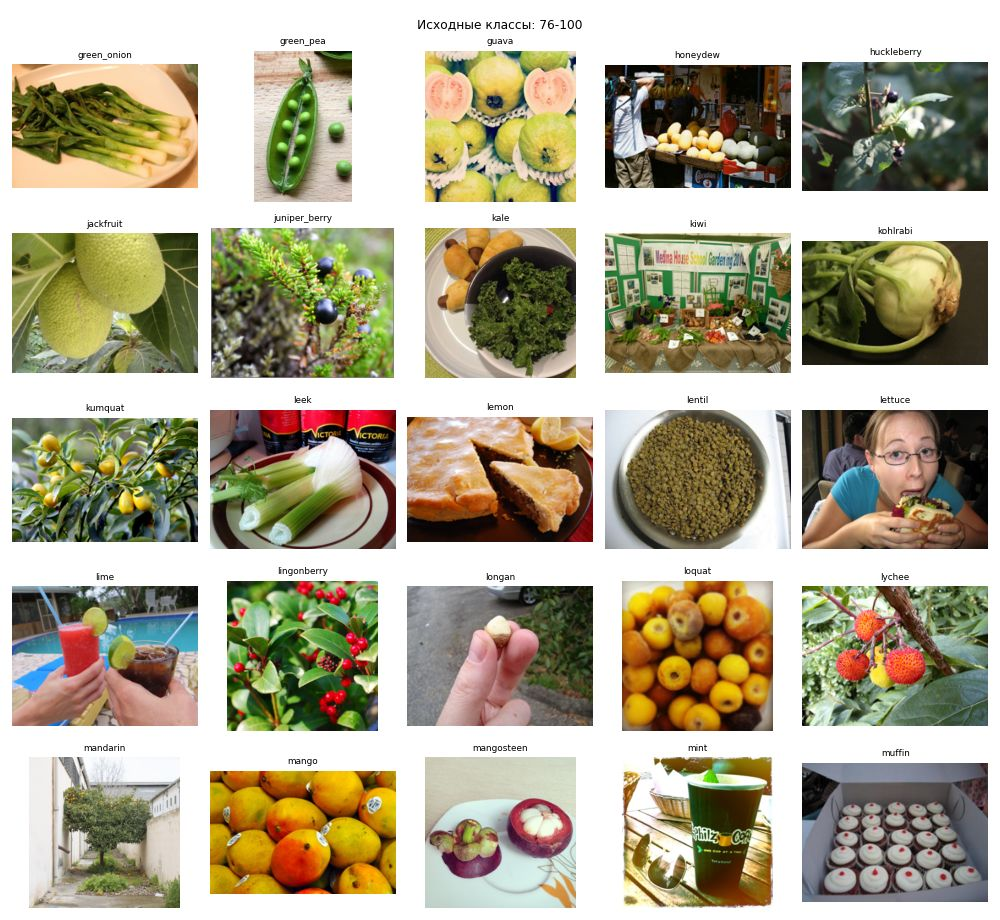

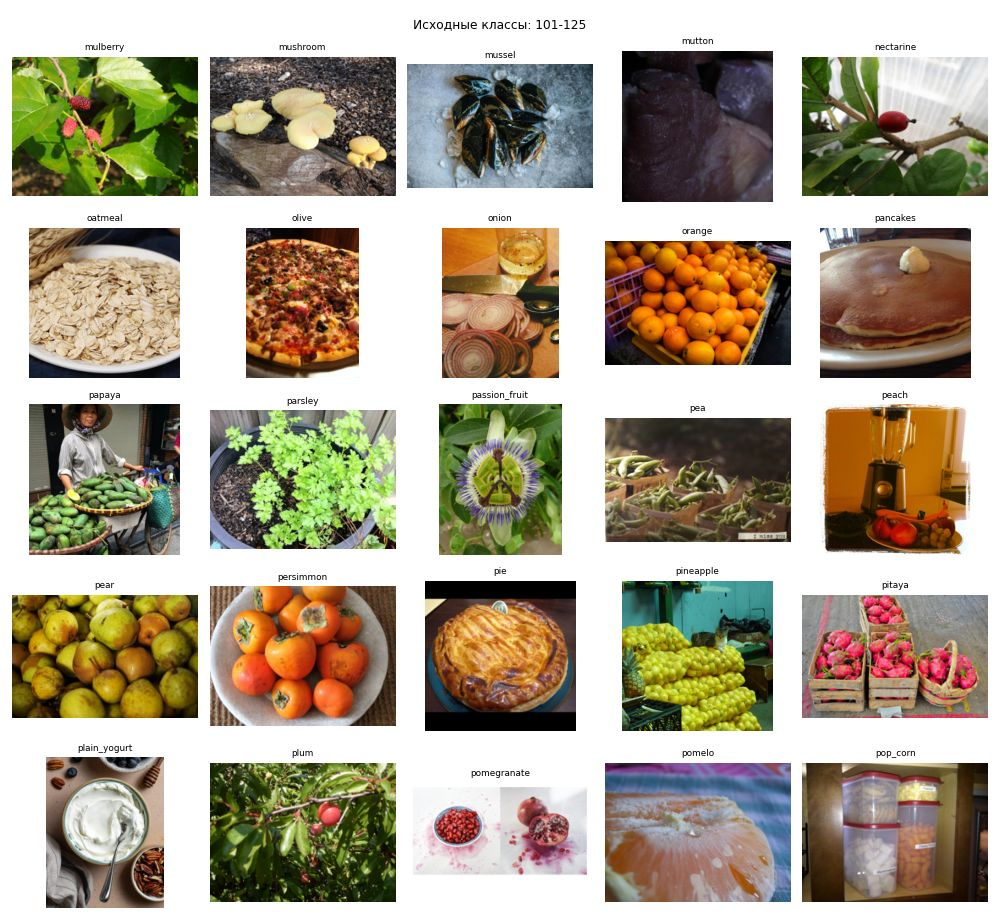

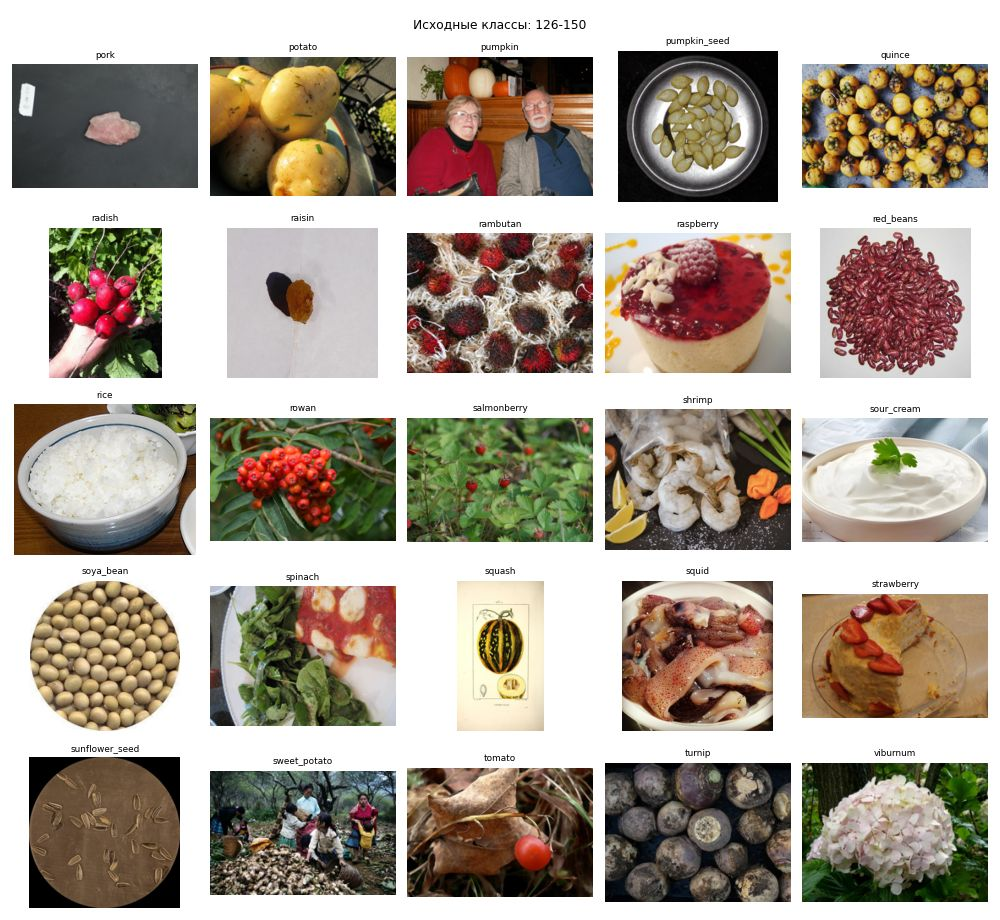

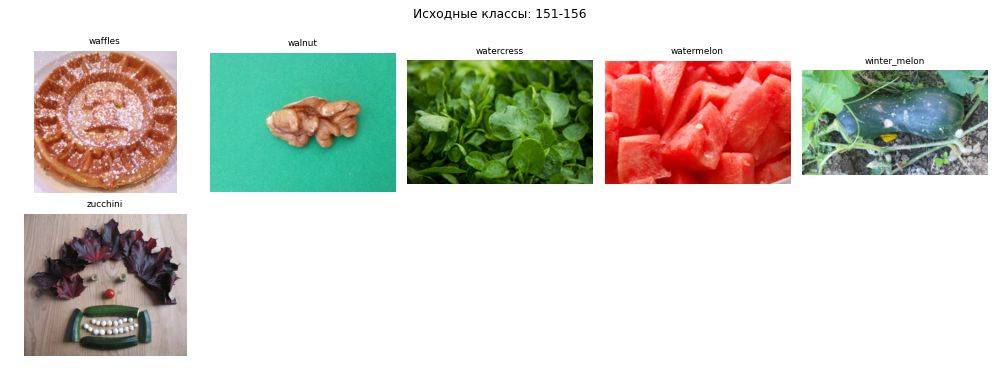

In [33]:
# Показываем примеры фотографий каждого класса.
def show_images(table, title, columns=5):
    """Показать сетку фотографий с подписями классов.

    Parameters
    ----------
    table : pandas.DataFrame
        Непустая таблица со столбцами path и class.
    title : str
        Общий заголовок сетки.
    columns : int, optional
        Положительное число столбцов; по умолчанию 5.

    Returns
    -------
    None
        Показывает сетку через show_preview.

    Notes
    -----
    Читает фотографии относительно DATA. Уменьшает их только в памяти.
    Ошибку открытия отдельного фото показывает вместо изображения.
    """

    rows = (len(table) + columns - 1) // columns
    fig, axes = plt.subplots(
        rows, columns, figsize=(columns * 2.5, rows * 2.3), squeeze=False
    )

    for ax in axes.flat:
        ax.axis("off")

    for ax, row in zip(axes.flat, table.to_dict("records")):
        try:
            with Image.open(DATA / row["path"]) as original:
                image = ImageOps.exif_transpose(original).convert("RGB")
                image.thumbnail((220, 220))
                ax.imshow(image)
            ax.set_title(row["class"], fontsize=8)

        except Exception as error:
            ax.set_title(str(error)[:35], fontsize=6)
    fig.suptitle(title, fontsize=11)
    plt.tight_layout()
    show_preview(fig)


examples = (
    metadata.groupby("class", group_keys=False)
    .sample(n=1, random_state=SEED)
    .sort_values("class")
)

for start in range(0, len(examples), 25):
    show_images(
        examples.iloc[start : start + 25],
        f"Исходные классы: {start + 1}-{min(start + 25, len(examples))}",
    )

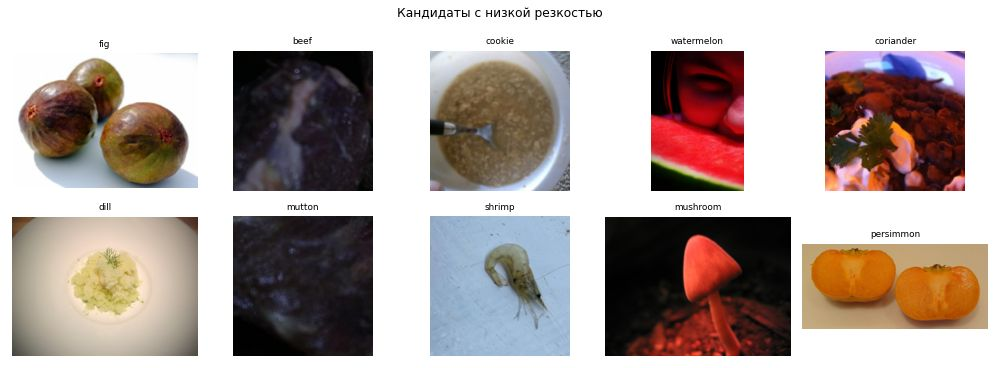

In [34]:
# Показываем кандидатов с низкой резкостью и отклонённые фотографии.
low_sharpness = quality.sort_values("sharpness").groupby("class", sort=False).head(3)
show_images(
    low_sharpness.sample(min(10, len(low_sharpness)), random_state=SEED),
    "Кандидаты с низкой резкостью",
)

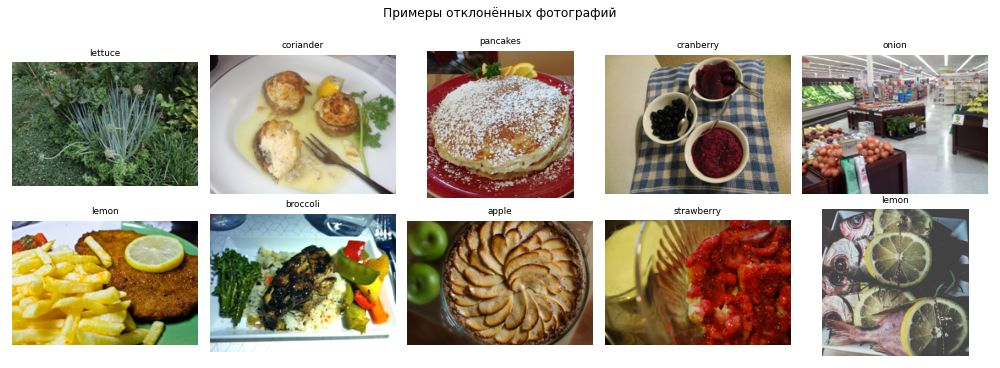

In [35]:
rejected_examples = review.loc[review["content_decision"].eq("reject")]
show_images(
    rejected_examples.sample(min(10, len(rejected_examples)), random_state=SEED),
    "Примеры отклонённых фотографий",
)

На исходных сетках видны конкретные проблемы: под меткой celery есть фото
субпродуктов с зеленью, под cherry встречаются кексы, под cucumber есть смешанный
салат. Такие примеры показывают, почему проверка одной структуры папок недостаточна.
В этих случаях прежняя ручная проверка подтвердила отклонение.

Два примера, blackberry с блинами и blueberry в выпечке, модель пропустила.
После просмотра в EDA добавляем отдельные ручные решения. Эти два решения записаны
прямо в ячейке выше и применяются при новом формировании разметки.
Исходные таблицы модели не меняются. Это небольшая целевая проверка, а не
случайная выборка для оценки точности.

Размытость оцениваем по дисперсии лапласиана после уменьшения до области
256 × 256 с сохранением пропорций. Однотонные объекты тоже могут давать
низкое значение. Автоматически по этому числу фотографии не исключаем.

## 6. Последовательный отбор и новая разметка

Для каждого исходного пути ведём журнал. Порядок исключений фиксирован:

1. Ошибки пути, метки, чтения или недопустимые значения характеристик.
2. Конфликты меток точных дублей и лишние точные копии.
3. Отклонённое содержимое по результатам модели и ручного просмотра.
4. Классы, которым пока не хватает фото или групп для оценки.

Причина указывается на первом шаге, где строка исключена. Поэтому суммы
по шагам не задваиваются. Полный результат содержательной проверки тоже
остаётся в таблице, даже если фото исключено раньше как дубль.
Ничего не удаляем из dataset/.

In [36]:
# Собираем метаданные и последовательно исключаем ошибки, точные копии и неподходящие фото.
data = metadata.merge(characteristics, on=["path", "class"], validate="one_to_one")

data = data.merge(
    quality[["path", "file_sha256", "pixel_sha256", "dhash", "sharpness"]],
    on="path",
    suffixes=("", "_quality"),
    validate="one_to_one",
)

data = data.merge(file_state, on="path", validate="one_to_one")

data = data.merge(
    review[
        [
            "path",
            "decision",
            "human_decision",
            "human_reason",
            "content_decision",
            "review_source",
        ]
    ],
    on="path",
    validate="one_to_one",
)

data["selection_status"] = "candidate"

data["excluded_at"] = ""

data["exclusion_reason"] = ""
flow = []


def exclude_rows(mask, stage, reason):
    """Исключить подходящие строки на текущем этапе отбора.

    Parameters
    ----------
    mask : pandas.Series
        Логическое условие с тем же индексом, что у data.
    stage : str
        Код этапа, который запишется в excluded_at.
    reason : str
        Причина для столбца exclusion_reason.

    Returns
    -------
    None
        Изменяет глобальную таблицу data и добавляет запись в список flow.

    Notes
    -----
    Обрабатывает только selection_status == candidate.
    Первую причину уже исключённых строк не перезаписывает.
    """

    active = data["selection_status"].eq("candidate")
    selected = active & mask.fillna(False)
    before = int(active.sum())

    data.loc[selected, "selection_status"] = "excluded"
    data.loc[selected, "excluded_at"] = stage
    data.loc[selected, "exclusion_reason"] = reason

    flow.append(
        {
            "stage": stage,
            "before": before,
            "excluded": int(selected.sum()),
            "remaining": before - int(selected.sum()),
        }
    )


technical_bad = (
    ~data["safe_path"]
    | ~data["exists"]
    | data["class"].isna()
    | data["class"].fillna("").str.strip().eq("")
    | data["error"].fillna("").ne("")
    | data["width"].le(0)
    | data["height"].le(0)
    | ~data["brightness"].between(0, 255)
    | data["path"].str.split("/").str[0].ne(data["class"])
)
exclude_rows(
    technical_bad, "1_technical", "Ошибка файла, пути, метки или характеристик"
)

parent = {path: path for path in data["path"]}


def find(path):
    """Найти представителя группы связанных путей.

    Parameters
    ----------
    path : str
        Путь, уже добавленный в словарь parent.

    Returns
    -------
    str
        Путь представителя группы.

    Notes
    -----
    Сокращает цепочки в глобальном parent для ускорения следующих поисков.

    Raises
    ------
    KeyError
        Если пути нет в parent.
    """

    while parent[path] != path:
        parent[path] = parent[parent[path]]
        path = parent[path]
    return path


def join_hash_groups(column):
    """Объединить группы фотографий с одинаковым непустым хешем.

    Parameters
    ----------
    column : str
        Имя столбца хеша в глобальной таблице data.

    Returns
    -------
    None
        Изменяет связи в parent, сами строки data не удаляет.

    Notes
    -----
    Использует find. Сохраняет связи, полученные на предыдущих вызовах.
    Одинаковый dHash означает предполагаемую связь, а не точный дубль.
    """

    seen = {}
    for path, value in data[["path", column]].itertuples(index=False, name=None):
        if pd.isna(value) or str(value) == "":
            continue

        if value in seen:
            first, second = find(path), find(seen[value])
            parent[first] = second
        else:
            seen[value] = path


join_hash_groups("file_sha256")
join_hash_groups("pixel_sha256")

data["exact_group"] = data["path"].map(find)

exact_class_count = data.groupby("exact_group")["class"].nunique()
conflict_groups = exact_class_count[exact_class_count.gt(1)].index
exclude_rows(
    data["exact_group"].isin(conflict_groups),
    "2a_exact_label_conflict",
    "Разные классы у одинакового изображения",
)

exact_content_count = data.groupby("exact_group")["content_decision"].nunique()
content_conflicts = exact_content_count[exact_content_count.gt(1)].index
exclude_rows(
    data["exact_group"].isin(content_conflicts),
    "2b_exact_review_conflict",
    "Разные решения отбора у точных копий",
)

active = data.loc[data["selection_status"].eq("candidate")].sort_values("path")
extra_paths = active.loc[active["exact_group"].duplicated(), "path"]
exclude_rows(
    data["path"].isin(extra_paths),
    "2c_exact_duplicates",
    "Лишняя точная копия; оставлен один экземпляр",
)

exclude_rows(
    data["content_decision"].eq("reject"),
    "3_content",
    "Отклонено при проверке содержимого",
)
assert (
    not data.loc[data["selection_status"].eq("candidate"), "content_decision"]
    .eq("pending")
    .any()
)
display(pd.DataFrame(flow))

,stage,before,excluded,remaining
0,1_technical,50080,0,50080
1,2a_exact_label_conflict,50080,0,50080
2,2b_exact_review_conflict,50080,0,50080
3,2c_exact_duplicates,50080,2,50078
4,3_content,50078,6608,43470


### Группы связанных снимков и малые классы

Для оценки числа групп дополнительно объединяем одинаковые dHash.
Такие фотографии считаем предположительно связанными, но не удаляем как дубли.
Группы строим на полной исходной сборке до исключений, чтобы удалённая копия
не разорвала известную связь.

Для первой версии обучения берём классы с минимум 20 оставленными фото и
пятью группами. Это рабочий порог для пилотной оценки, а не гарантия достаточного
объёма. Остальные классы сохраняем в журнале и откладываем до пополнения.

In [37]:
# Формируем группы связанных снимков и откладываем малые классы.
join_hash_groups("dhash")

data["group_id"] = data["path"].map(
    lambda path: "g_" + hashlib.sha256(find(path).encode()).hexdigest()[:16]
)

data["group_method"] = "exact_hashes_and_equal_dhash"

remaining = data.loc[data["selection_status"].eq("candidate")]
class_inventory = remaining.groupby("class").agg(
    images=("path", "size"), known_groups=("group_id", "nunique")
)

class_inventory["eligible"] = (class_inventory["images"] >= MIN_IMAGES) & (
    class_inventory["known_groups"] >= MIN_GROUPS
)

postponed = class_inventory.loc[~class_inventory["eligible"]].sort_values("images")
exclude_rows(
    data["class"].isin(postponed.index),
    "4_postponed_class",
    "Пока мало фото или известных групп",
)
display(postponed.head(20))

,images,known_groups,eligible
class,,,
arugula,2,2,False
feijoa,2,2,False
pomelo,2,2,False
nectarine,2,2,False
quince,2,2,False
kohlrabi,3,3,False
honeydew,3,3,False
celery,3,3,False
watercress,3,3,False


In [38]:
print("Отложено классов:", len(postponed))

Отложено классов: 50


In [39]:
print("Оставлено после отбора:", data["selection_status"].eq("candidate").sum())

Оставлено после отбора: 43004


In [40]:
display(pd.DataFrame(flow))

,stage,before,excluded,remaining
0,1_technical,50080,0,50080
1,2a_exact_label_conflict,50080,0,50080
2,2b_exact_review_conflict,50080,0,50080
3,2c_exact_duplicates,50080,2,50078
4,3_content,50078,6608,43470
5,4_postponed_class,43470,466,43004


In [41]:
# Завершаем отбор и выделяем принятые фотографии без разделения на выборки.
data.loc[data["selection_status"].eq("candidate"), "selection_status"] = "keep"
clean = data.loc[data["selection_status"].eq("keep")].copy()
assert not clean["path"].duplicated().any()

## 7. Итоговые метаданные

Сохраняем один `processed/metadata.csv`. В нём есть все исходные фотографии,
характеристики, решения модели и человека, причина исключения и группа связанных снимков.
Строки с `selection_status == "keep"` составляют версию для обучения.
Остальные строки сохраняют историю отбора, но в обучение не попадают.

Таблицы статистик, графики и список классов остаются внутри ноутбука.
При новом запуске всё рассчитывается из исходного датасета и результатов проверки.

In [42]:
# Сохраняем итоговую разметку и сравниваем объём данных до и после отбора.
output_columns = [
    "path",
    "class",
    "group_id",
    "group_method",
    "selection_status",
    "excluded_at",
    "exclusion_reason",
    "decision",
    "human_decision",
    "human_reason",
    "content_decision",
    "review_source",
    "width",
    "height",
    "format",
    "color_mode",
    "brightness",
    "file_sha256",
    "pixel_sha256",
    "dhash",
]

data[
    output_columns
    + [
        "aspect_ratio",
        "resolution_mp",
        "file_size_kb",
        "sharpness",
        "error",
        "warnings",
    ]
].to_csv(PROCESSED / "metadata.csv", index=False, encoding="utf-8-sig")

flow_table = pd.DataFrame(flow)
class_to_idx = {name: i for i, name in enumerate(sorted(clean["class"].unique()))}
display(flow_table)

,stage,before,excluded,remaining
0,1_technical,50080,0,50080
1,2a_exact_label_conflict,50080,0,50080
2,2b_exact_review_conflict,50080,0,50080
3,2c_exact_duplicates,50080,2,50078
4,3_content,50078,6608,43470
5,4_postponed_class,43470,466,43004


In [43]:
assert len(clean) + data["selection_status"].eq("excluded").sum() == len(metadata)

comparison = (
    pd.DataFrame(
        {
            "raw": raw_counts,
            "after_content": review.loc[
                review["content_decision"].eq("keep"), "class"
            ].value_counts(),
            "training_version": clean["class"].value_counts(),
        }
    )
    .fillna(0)
    .astype(int)
)
display(comparison.head(15))

,raw,after_content,training_version
class,,,
almond,492,492,492
apple,773,633,633
apricot,12,9,0
artichoke,203,177,177
arugula,16,2,0
asparagus,317,154,154
avocado,67,31,31
banana,611,430,430
basil,103,84,84


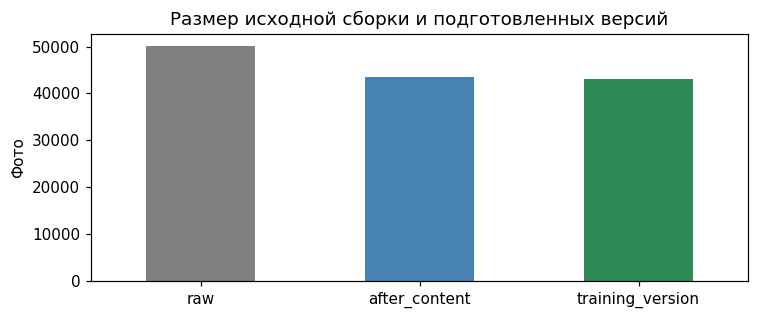

In [44]:
comparison.sum().plot.bar(figsize=(7, 3), color=["gray", "steelblue", "seagreen"])
plt.ylabel("Фото")
plt.title("Размер исходной сборки и подготовленных версий")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
plt.close()

In [45]:
training_metadata = pd.read_csv(PROCESSED / "metadata.csv", low_memory=False)
training_metadata = training_metadata.loc[
    training_metadata["selection_status"].eq("keep")
]
assert len(training_metadata) == len(clean)
print("Сохранён один CSV:", len(data), "строк; для обучения:", len(training_metadata))

Сохранён один CSV: 50080 строк; для обучения: 43004


## 8. Проверка аугментаций

На отобранных фотографиях сравниваем горизонтальное отражение, поворот
на 10 градусов и снижение яркости до 85% от исходной. Такие преобразования
могут помочь при смене ракурса и освещения. В показанных примерах продукт
остаётся различимым. При обучении будем применять их случайно только к обучающим фотографиям.

Сильные изменения цвета пока не используем: цвет помогает различать продукты.
Сильная обрезка может убрать часть продукта или другую еду на фоне.
Отражение также требует осторожности на фото упаковок с надписями.
Эти преобразования не создают новые независимые сцены.

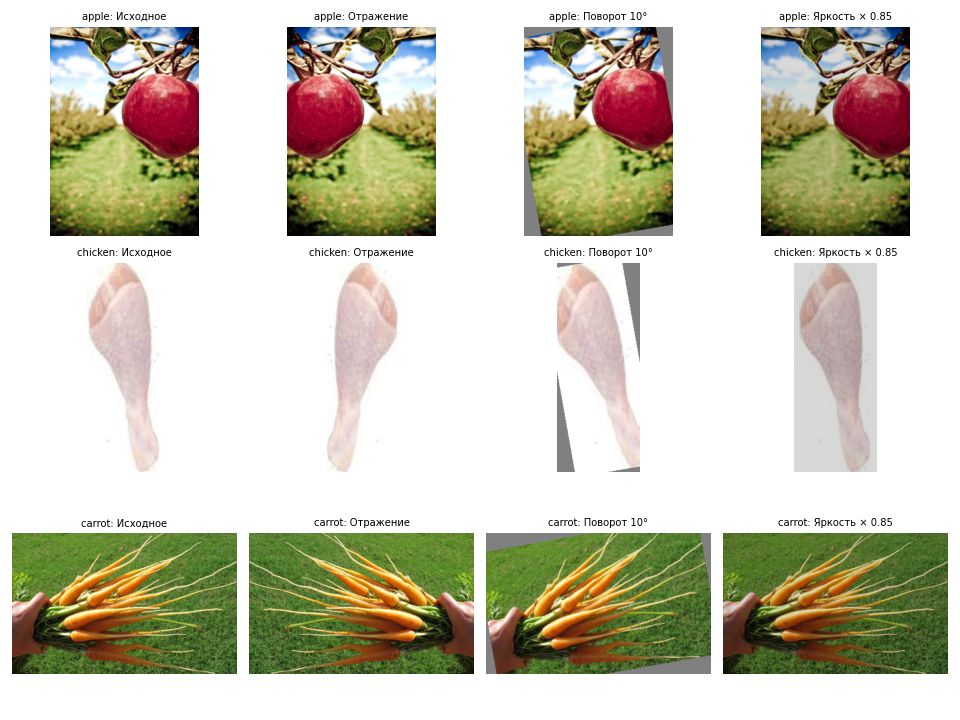

In [46]:
# Сравниваем простые аугментации на отобранных фотографиях.
aug_rows = []
for class_name in ["apple", "chicken", "carrot"]:
    part = clean.loc[clean["class"].eq(class_name)]
    if not part.empty:
        aug_rows.append(part.sample(1, random_state=SEED).iloc[0])

fig, axes = plt.subplots(
    len(aug_rows), 4, figsize=(12, 3 * len(aug_rows)), squeeze=False
)
for row_index, row in enumerate(aug_rows):
    with Image.open(DATA / row["path"]) as original:
        image = ImageOps.exif_transpose(original).convert("RGB")
        image.thumbnail((350, 350))

        variants = [
            ("Исходное", image),
            ("Отражение", ImageOps.mirror(image)),
            (
                "Поворот 10°",
                image.rotate(
                    10, resample=Image.Resampling.BILINEAR, fillcolor=(128, 128, 128)
                ),
            ),
            ("Яркость × 0.85", ImageEnhance.Brightness(image).enhance(0.85)),
        ]
        for ax, (title, variant) in zip(axes[row_index], variants):
            ax.imshow(variant)
            ax.set_title(f"{row['class']}: {title}", fontsize=9)
            ax.axis("off")
plt.tight_layout()
show_preview(fig)